In [45]:
from ISLP import load_data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error

In [ ]:
df = load_data('Auto').reset_index()
df.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
1,buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
2,plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
3,amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
4,ford torino,17.0,8,302.0,140,3449,10.5,70,1


In [36]:
X = df.drop(columns=['mpg', 'name'], axis=1)
y = df['mpg']


In [ ]:
scale_cols = ['weight', 'acceleration', 'cylinders', 'displacement', 'horsepower','year']
poly_cols = ['horsepower', 'weight', 'displacement']

preprocessor = ColumnTransformer([
    ('poly', PolynomialFeatures(degree=3, include_bias=False), poly_cols),
    ('cat', OneHotEncoder(drop='first'), ['origin'])
], remainder='passthrough')

X_scaled = preprocessor.fit_transform(X)

x_train, x_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=0)

In [91]:
from lazypredict.Supervised import LazyRegressor

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize
model = LazyRegressor()

# Fit & compare models
models, predictions = model.fit(X_train, X_test, y_train, y_test)

# View results
print(models)

  0%|          | 0/42 [00:00<?, ?it/s]

/opt/anaconda3/envs/DSMLenv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000260 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 283
[LightGBM] [Info] Number of data points in the train set: 313, number of used features: 7
[LightGBM] [Info] Start training from score 23.599361
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

/opt/anaconda3/envs/DSMLenv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [90]:
model = LinearRegression().fit(x_train, y_train)
print(model.score(x_test, y_test))
print(root_mean_squared_error(model.predict(x_test), y_test))

0.8814718332609447
2.714250453193471


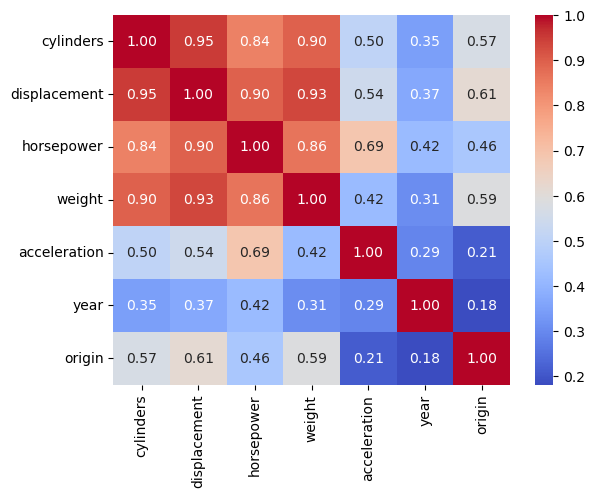

In [59]:
sns.heatmap(X.corr().abs(), annot=True, fmt='.2f', cmap='coolwarm');

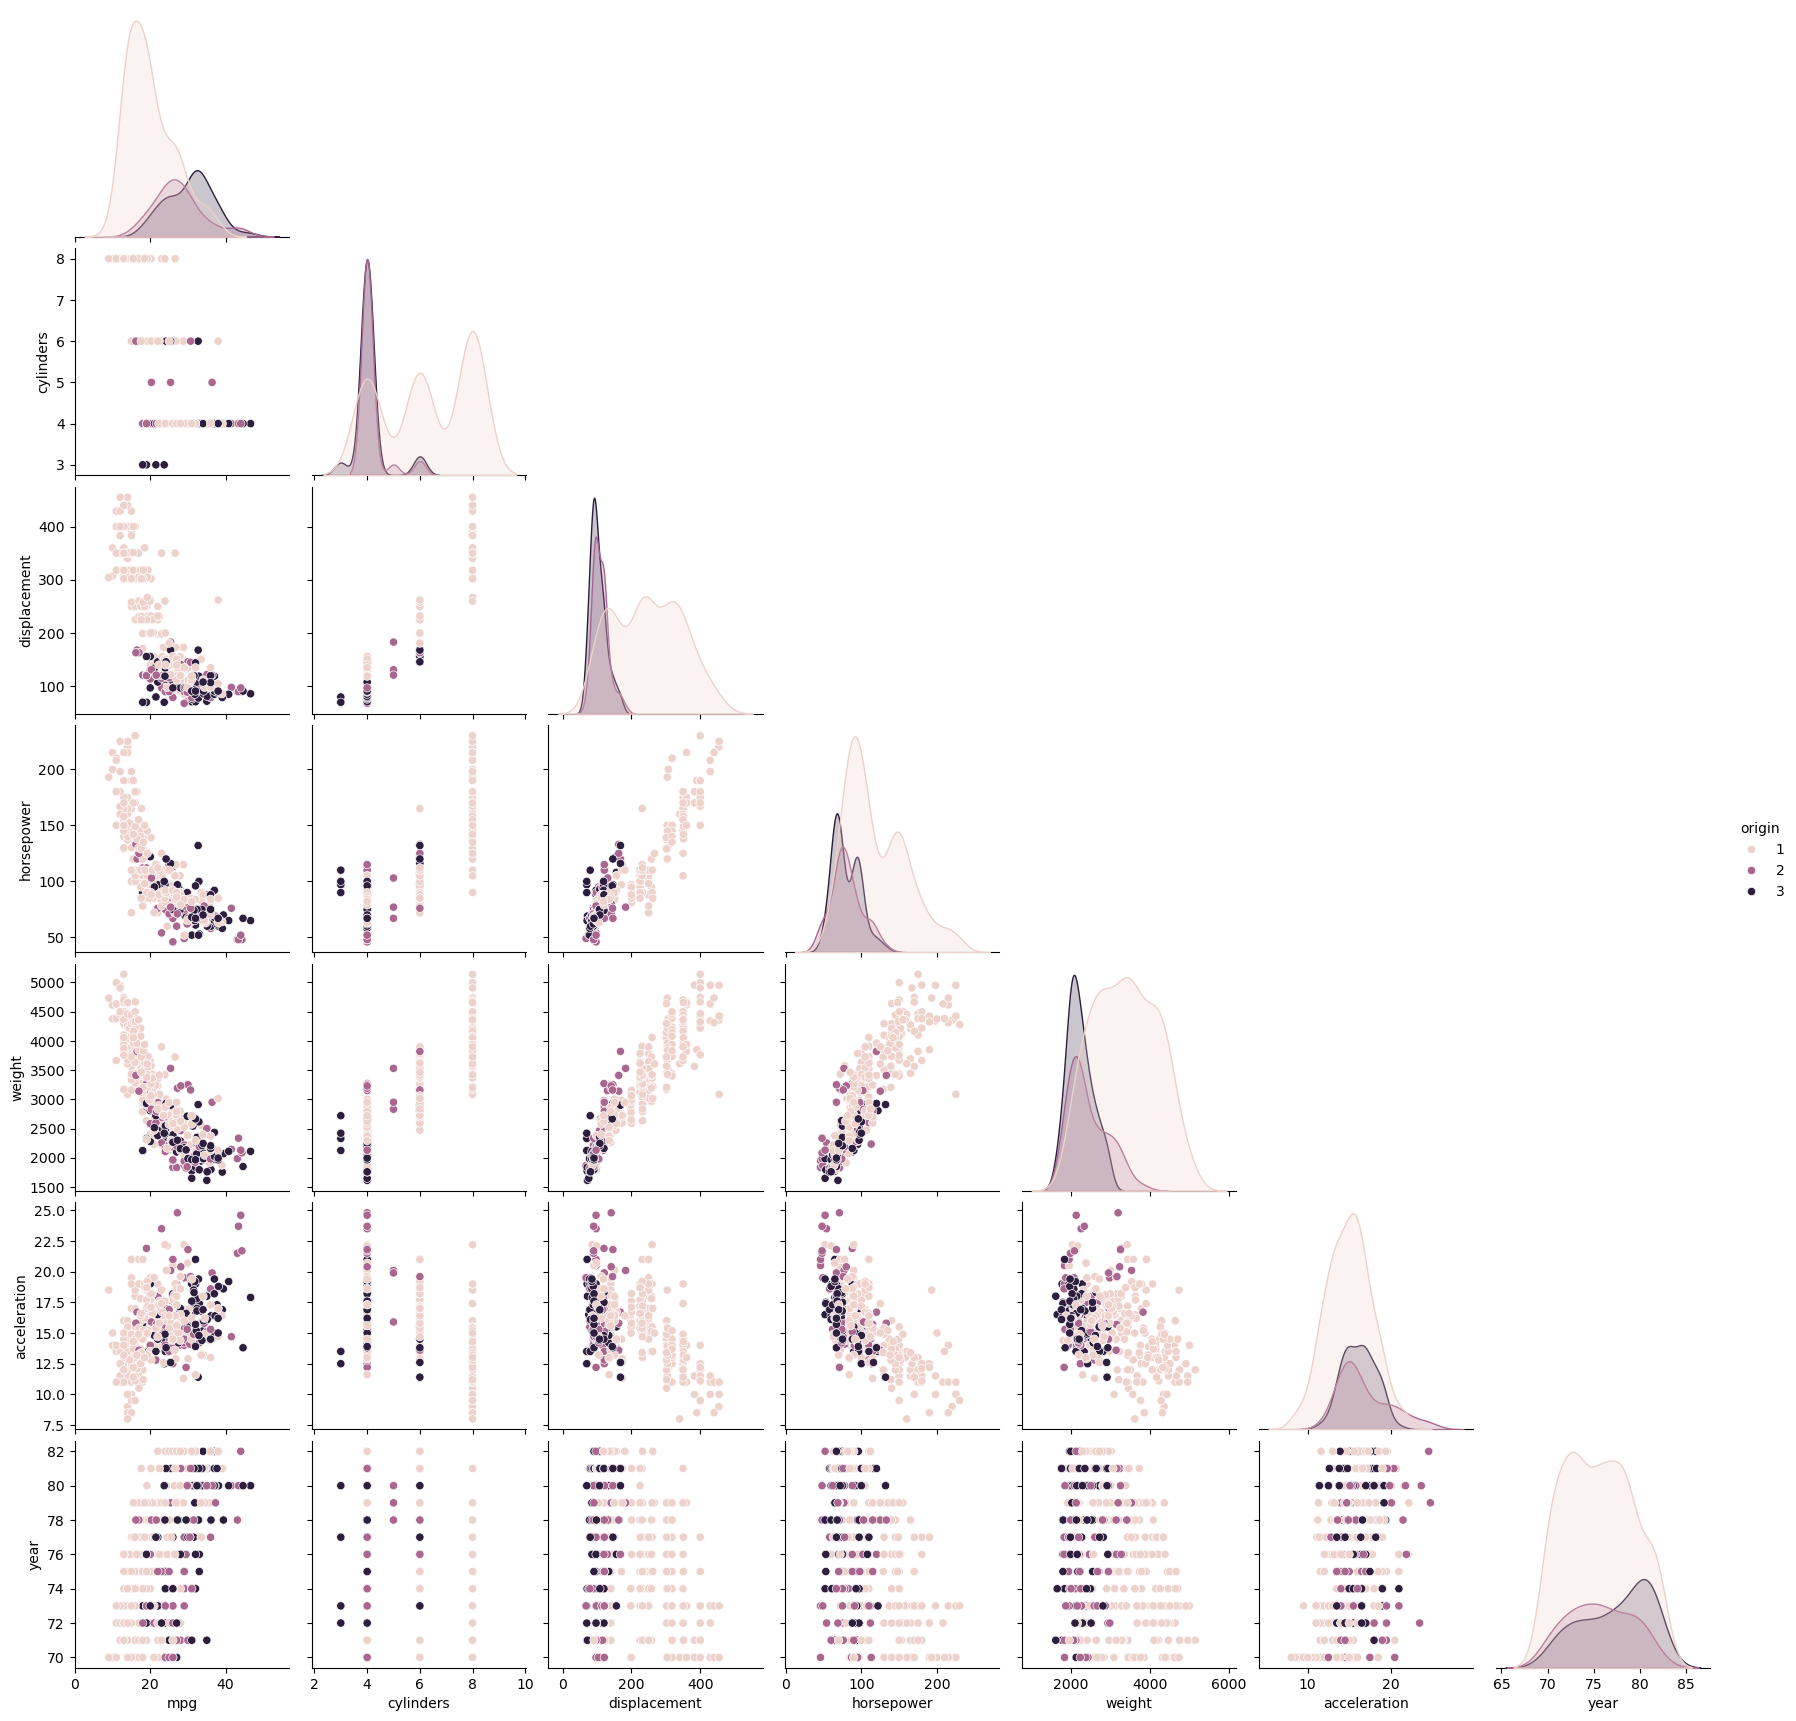

In [60]:
sns.pairplot(df, corner=True, hue='origin');